# Analysing Pharmaceutical Sales Data
**Author:** Tehan Wijeratne

## Project Overview

This project analyses daily pharmaceutical sales from 2 January 2014 to 8 October 2019 (2,106 days). The dataset contains 8 drug categories, identified by ATC codes, which are groups of drugs and not individual brands.

**Dataset source:** https://www.kaggle.com/datasets/milanzdravkovic/pharma-sales-data

**Questions I set out to answer:**
1. What are the total sales for each drug category?
2. Which individual drug brands have the highest total sales? (not possible, see the note below)
3. What are the top three drugs in January 2015, July 2016 and September 2017?
4. Which drug was sold most often in 2017?
5. Which drug category has the highest average daily sales?
6. Are respiratory drugs (R03) sold more during specific months?

**Important:** The dataset has no brand names, so questions 2, 3 and 4 were answered at the category level.

**Tools:** Python, Pandas, Matplotlib and Jupyter Notebook.

### Key findings at a glance
- N02BE sold the most: 49.4% of all sales, and it was first (with N05B second) in every year from 2014 to 2019.
- In 2017, N02BE was the top category by total quantity and by number of days with sales (361 of 365).
- R03 sales are seasonal. Using the complete years 2015 to 2018, R03 averaged 7.03 per day from October to April and 3.98 per day from May to September, with December the highest month and July the lowest.
- The data can show *when* sales are higher, but not *why*.

## 1. Understanding the Dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

df = pd.read_csv("../data/salesdaily.csv")
df.head()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
0,1/2/2014,0.0,3.67,3.4,32.40,7.0,0.0,0.0,2.0,2014,1,248,Thursday
1,1/3/2014,8.0,4.00,4.4,50.60,16.0,0.0,20.0,4.0,2014,1,276,Friday
2,1/4/2014,2.0,1.00,6.5,61.85,10.0,0.0,9.0,1.0,2014,1,276,Saturday
3,1/5/2014,4.0,3.00,7.0,41.10,8.0,0.0,3.0,0.0,2014,1,276,Sunday
4,1/6/2014,5.0,1.00,4.5,21.70,16.0,2.0,6.0,2.0,2014,1,276,Monday


In [2]:
df.tail()

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name
2101,10/4/2019,7.34,5.683,2.25,22.45,13.0,0.0,1.0,1.00,2019,10,276,Friday
2102,10/5/2019,3.84,5.010,6.00,25.40,7.0,0.0,0.0,0.33,2019,10,276,Saturday
2103,10/6/2019,4.00,11.690,2.00,34.60,6.0,0.0,5.0,4.20,2019,10,276,Sunday
2104,10/7/2019,7.34,4.507,3.00,50.80,6.0,0.0,10.0,1.00,2019,10,276,Monday
2105,10/8/2019,0.33,1.730,0.50,44.30,20.0,2.0,2.0,0.00,2019,10,190,Tuesday


In [3]:
df.shape

(2106, 13)

In [4]:
df.columns

Index(['datum', 'M01AB', 'M01AE', 'N02BA', 'N02BE', 'N05B', 'N05C', 'R03',
       'R06', 'Year', 'Month', 'Hour', 'Weekday Name'],
      dtype='str')

The table has 2,106 rows and 13 columns: a date column (`datum`), eight ATC drug-category columns (`M01AB` to `R06`), and `Year`, `Month`, `Hour` and `Weekday Name`. There are only category codes, no individual drug or brand names.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2106 entries, 0 to 2105
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datum         2106 non-null   str    
 1   M01AB         2106 non-null   float64
 2   M01AE         2106 non-null   float64
 3   N02BA         2106 non-null   float64
 4   N02BE         2106 non-null   float64
 5   N05B          2106 non-null   float64
 6   N05C          2106 non-null   float64
 7   R03           2106 non-null   float64
 8   R06           2106 non-null   float64
 9   Year          2106 non-null   int64  
 10  Month         2106 non-null   int64  
 11  Hour          2106 non-null   int64  
 12  Weekday Name  2106 non-null   str    
dtypes: float64(8), int64(3), str(2)
memory usage: 214.0 KB


In [6]:
df.isna().sum()

datum           0
M01AB           0
M01AE           0
N02BA           0
N02BE           0
N05B            0
N05C            0
R03             0
R06             0
Year            0
Month           0
Hour            0
Weekday Name    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

There are no missing values and no duplicate rows. The `datum` column is stored as text, so it needs converting to a real date (done in Section 2).

In [8]:
df.describe()

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour
count,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000
mean,5.033683,3.895830,3.880441,29.917095,8.853627,0.593522,5.512262,2.900198,2016.401235,6.344255,275.945869
std,2.737579,2.133337,2.384010,15.590966,5.605605,1.092988,6.428736,2.415816,1.665060,3.386954,1.970547
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2014.000000,1.000000,190.000000
25%,3.000000,2.340000,2.000000,19.000000,5.000000,0.000000,1.000000,1.000000,2015.000000,3.000000,276.000000
50%,4.990000,3.670000,3.500000,26.900000,8.000000,0.000000,4.000000,2.000000,2016.000000,6.000000,276.000000
75%,6.670000,5.138000,5.200000,38.300000,12.000000,1.000000,8.000000,4.000000,2018.000000,9.000000,276.000000
max,17.340000,14.463000,16.000000,161.000000,54.833333,9.000000,45.000000,15.000000,2019.000000,12.000000,276.000000


In [9]:
drug_cols = ["M01AB", "M01AE", "N02BA", "N02BE", "N05B", "N05C", "R03", "R06"]

df[drug_cols].describe()

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
count,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000,2106.000000
mean,5.033683,3.895830,3.880441,29.917095,8.853627,0.593522,5.512262,2.900198
std,2.737579,2.133337,2.384010,15.590966,5.605605,1.092988,6.428736,2.415816
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.000000,2.340000,2.000000,19.000000,5.000000,0.000000,1.000000,1.000000
50%,4.990000,3.670000,3.500000,26.900000,8.000000,0.000000,4.000000,2.000000
75%,6.670000,5.138000,5.200000,38.300000,12.000000,1.000000,8.000000,4.000000
max,17.340000,14.463000,16.000000,161.000000,54.833333,9.000000,45.000000,15.000000


In [10]:
# Max divided by the 75% value: which categories have days far above their typical level?
df[drug_cols].max() / df[drug_cols].quantile(0.75)

M01AB    2.599700
M01AE    2.814909
N02BA    3.076923
N02BE    4.203655
N05B     4.569444
N05C     9.000000
R03      5.625000
R06      3.750000
dtype: float64

N02BE has the highest mean (29.92) and N05C the lowest (0.59). N05C is zero on at least half of all days (its median is 0). Every category has some days well above its typical level, for example N02BE's maximum of 161 against a 75% value of 38.3. N05C's ratio of 9.0 looks large only because its 75% value is just 1, so the ratio can mislead when the base is small.

## 2. Data Cleaning

The checks above found no missing values and no duplicates, so the remaining work is the date column and a look at zeros and unusual values.

### Converting the date column

In [11]:
df["datum"] = pd.to_datetime(df["datum"], format="%m/%d/%Y")
df.dtypes

datum           datetime64[us]
M01AB                  float64
M01AE                  float64
N02BA                  float64
N02BE                  float64
N05B                   float64
N05C                   float64
R03                    float64
R06                    float64
Year                     int64
Month                    int64
Hour                     int64
Weekday Name               str
dtype: object

In [12]:
df["datum"].min(), df["datum"].max()

(Timestamp('2014-01-02 00:00:00'), Timestamp('2019-10-08 00:00:00'))

In [13]:
df["datum"].dt.month.equals(df["Month"])

False

In [14]:
df["datum"].dt.month.dtype, df["Month"].dtype

(dtype('int32'), dtype('int64'))

In [15]:
(df["datum"].dt.month == df["Month"]).sum(), len(df)

(np.int64(2106), 2106)

In [16]:
df[df["datum"].dt.month != df["Month"]]

,datum,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06,Year,Month,Hour,Weekday Name


`.equals()` returned False only because the two columns use different integer types (int32 vs int64). Comparing the values directly shows the months match on every row, so the month/day/year format is correct.

### Is the timeline complete and in order?

In [17]:
df["datum"].is_monotonic_increasing

True

In [18]:
df["datum"].is_unique

True

In [19]:
expected_days = (df["datum"].max() - df["datum"].min()).days + 1
expected_days, len(df)

(2106, 2106)

In [20]:
(df["datum"].dt.year == df["Year"]).all()

np.True_

In [21]:
(df["datum"].dt.day_name() == df["Weekday Name"]).all()

np.True_

### Zeros, extreme days and decimal values

In [22]:
(df[drug_cols] == 0).sum()

M01AB      40
M01AE      36
N02BA      78
N02BE      26
N05B       43
N05C     1430
R03       484
R06       256
dtype: int64

In [23]:
((df[drug_cols] == 0).mean() * 100).round(1)

M01AB     1.9
M01AE     1.7
N02BA     3.7
N02BE     1.2
N05B      2.0
N05C     67.9
R03      23.0
R06      12.2
dtype: float64

In [24]:
df.nlargest(5, "N02BE")[["datum", "Weekday Name", "N02BE"]]

,datum,Weekday Name,N02BE
1093,2016-12-30,Friday,161.00
1094,2016-12-31,Saturday,108.70
1851,2019-01-27,Sunday,100.10
1850,2019-01-26,Saturday,97.80
1844,2019-01-20,Sunday,93.05


In [25]:
df.nlargest(5, "R03")[["datum", "Weekday Name", "R03"]]

,datum,Weekday Name,R03
1857,2019-02-02,Saturday,45.0
1476,2018-01-17,Wednesday,41.0
1593,2018-05-14,Monday,37.0
809,2016-03-21,Monday,36.0
1883,2019-02-28,Thursday,35.0


In [26]:
(df[drug_cols] % 1 != 0).sum()

M01AB    1266
M01AE    1810
N02BA     898
N02BE    1256
N05B       67
N05C       27
R03        38
R06       272
dtype: int64

### Summary of cleaning decisions

Before doing any analysis, I checked the data to see if it can be trusted. This is what I found and what I did.

- **Dates:** The `datum` column was stored as text, so I converted it into a proper date using the month/day/year format. I checked the format was right: all 2106 rows converted without errors, the first and last dates matched (2 Jan 2014 to 8 Oct 2019), and the Month, Year and Weekday columns matched the new dates on every row. The `.equals()` check showed False at first, but that was only because of int32 vs int64. The values were the same.
- **Missing values and duplicates:** There are none. Every column has 2106 values and no row is repeated.
- **Completeness:** The dates are in order and none repeat. There are 2106 days between the first and last date and 2106 rows, so there is exactly one row per day with no gaps.
- **Zeros and extreme days (kept):** There are no negative values, so nothing looked like an error. A zero means nothing was sold that day (N05C is zero on 67.9% of days), and high days like N02BE's 161 on 30 Dec 2016 look like real events. Deleting them would change the results, so I kept them.
- **Things I can't confirm:** The `Hour` column has no explanation in the dataset, so I'm not using it. The sales quantities are not always whole numbers (M01AE has decimals on 1810 of 2106 days) and the unit is not documented.

Only the copy of the data in memory was changed. The original CSV file was not touched.

## 3. Exploratory Data Analysis

This section explores the data with filtering, sorting, grouping and aggregation, before answering the six questions.

### Filtering and sorting

In [27]:
df[df["Year"] == 2017].shape

(365, 13)

In [28]:
df[(df["Year"] == 2017) & (df["Month"] == 7)][["datum", "R03", "R06"]].head()

,datum,R03,R06
1276,2017-07-01,10.0,4.0
1277,2017-07-02,0.0,4.0
1278,2017-07-03,11.0,0.0
1279,2017-07-04,0.0,6.0
1280,2017-07-05,22.0,6.0


In [29]:
df.sort_values("N02BE", ascending=False)[["datum", "N02BE"]].head(3)

,datum,N02BE
1093,2016-12-30,161.0
1094,2016-12-31,108.7
1851,2019-01-27,100.1


2017 has exactly 365 rows, a full year. The three highest N02BE days are 30 Dec 2016 (161.0), 31 Dec 2016 (108.7) and 27 Jan 2019 (100.1).

### Grouping by year

In [30]:
df.groupby("Year")["R03"].sum()

Year
2014    1255.000000
2015    1721.250000
2016    2137.000000
2017    1893.614583
2018    2655.250000
2019    1946.708333
Name: R03, dtype: float64

In [31]:
df.groupby("Year")["R03"].mean()

Year
2014    3.447802
2015    4.715753
2016    5.838798
2017    5.187985
2018    7.274658
2019    6.927788
Name: R03, dtype: float64

In [32]:
df.groupby("Year")["R03"].count()

Year
2014    364
2015    365
2016    366
2017    365
2018    365
2019    281
Name: R03, dtype: int64

The years do not have the same number of days: 2014 has 364 (the data starts on 2 January), 2016 has 366 (a leap year) and 2019 has only 281 (the data ends on 8 October). Yearly totals are therefore not directly comparable, so the daily mean is the fairer measure.

### Aggregating across all drug categories

In [33]:
df[drug_cols].agg(["sum", "mean", "median", "max"]).round(2)

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
sum,10600.94,8204.62,8172.21,63005.40,18645.74,1249.96,11608.82,6107.82
mean,5.03,3.90,3.88,29.92,8.85,0.59,5.51,2.90
median,4.99,3.67,3.50,26.90,8.00,0.00,4.00,2.00
max,17.34,14.46,16.00,161.00,54.83,9.00,45.00,15.00


### Month coverage and the year-by-month pattern

In [34]:
df.groupby("Month")["datum"].count()

Month
1     185
2     169
3     186
4     180
5     186
6     180
7     186
8     186
9     180
10    163
11    150
12    155
Name: datum, dtype: int64

In [35]:
df.groupby(["Year", "Month"])["R03"].mean().round(2).unstack()

Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2014,3.73,4.36,3.61,3.23,3.45,1.90,1.97,1.19,3.83,5.16,3.73,5.26
2015,5.72,7.43,5.48,3.23,3.23,6.43,1.94,1.45,3.03,5.94,5.50,7.45
2016,5.61,8.45,8.16,7.20,4.23,4.23,3.52,3.74,4.03,7.10,5.00,8.87
2017,6.34,5.01,3.52,6.03,4.13,5.43,3.71,2.42,4.63,7.97,6.53,6.58
2018,7.06,8.01,8.68,7.63,5.39,3.37,2.90,5.13,6.83,10.55,10.37,11.42
2019,12.45,8.07,8.29,7.30,9.62,4.73,3.71,4.68,4.05,4.62,NaN,NaN


In [36]:
monthly = df.groupby(["Year", "Month"])["R03"].mean().unstack()
monthly.idxmax(axis=1)

Year
2014    12
2015    12
2016    12
2017    10
2018    12
2019     1
dtype: int64

In [37]:
monthly.idxmin(axis=1)

Year
2014    8
2015    8
2016    7
2017    8
2018    7
2019    7
dtype: int64

October (163 days), November (150) and December (155) have fewer days than the other months because 2019 has only 8 days of October and no November or December. In the year-by-month table, November and December 2019 are empty, and the October 2019 value covers only 8 days. December is the highest month in 2014, 2015, 2016 and 2018 (October in 2017, January in 2019). July or August is the lowest month in every year.

## 4. Question 1: Total sales for each drug category

**Approach:** add up each category over all days, then work out its share of the grand total.

In [38]:
totals = df[drug_cols].sum().sort_values(ascending=False)
shares = (totals / totals.sum() * 100).round(1)
shares

N02BE    49.4
N05B     14.6
R03       9.1
M01AB     8.3
M01AE     6.4
N02BA     6.4
R06       4.8
N05C      1.0
dtype: float64

In [39]:
# Check: do the shares add up to 100?
(totals / totals.sum() * 100).sum().round(1) == 100

np.True_

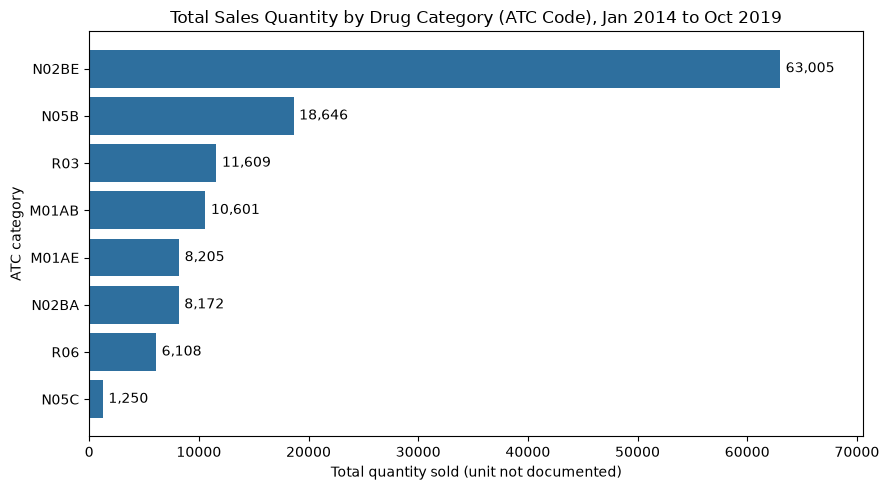

In [40]:
fig, ax = plt.subplots(figsize=(9, 5))

plot_totals = totals.sort_values()

ax.barh(plot_totals.index, plot_totals.values, color="#2E6F9E")

ax.set_title("Total Sales Quantity by Drug Category (ATC Code), Jan 2014 to Oct 2019")
ax.set_xlabel("Total quantity sold (unit not documented)")
ax.set_ylabel("ATC category")

for i, v in enumerate(plot_totals.values):
    ax.text(v + 500, i, f"{v:,.0f}", va="center")

ax.set_xlim(0, plot_totals.max() * 1.12)

plt.tight_layout()
plt.savefig("../visualisations/q1_total_sales_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart 1:** N02BE sold far more than any other category, about 49% of all sales. N05C sold the least.

**Finding:** N02BE sold the most by far, with 63,005 units, which is 49.4% of all sales, so almost half of everything sold comes from this one category. N05B comes next with 18,646 units (14.6%), then R03 with 11,609 units (9.1%). N05C sold the least with only 1,250 units, just 1.0% of the total. M01AE and N02BA are almost the same (6.4% each).

**Limitations:**
- The dataset doesn't say what the unit is. It could be packs, tablets or something else, and many values are decimals, so I can't say "units of what". Because of this, comparing categories assumes they are all measured the same way, which I can't confirm.
- These are drug **categories**, not individual brands, so I can only say which category sold the most, not which drug.
- The period is not a clean set of full years. The data starts on 2 Jan 2014 and ends on 8 Oct 2019, so the totals cover 2,106 days.
- The dataset doesn't say which pharmacy or area the sales come from, so the results may not apply to other places.
- N05C is zero on 67.9% of days. Its low total mostly reflects days with no sales, and I can't tell if that is low demand or low stock.

## 5. Question 2: Which individual drug brands sold the most? (answered at category level)

**Important:** This dataset doesn't have any brand names. The columns are ATC codes, which are drug **categories**, not individual brands. So I can't answer this question exactly as it is written, and I didn't want to pretend a category is a brand. Instead, I answered the closest question I can: which drug **categories** sold the most?

**Approach:** I took the top 3 categories by total sales, then checked if the top category stays the same in every year using the daily average per year. I used the average because the years have different numbers of days.

In [41]:
totals.nlargest(3)

N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
dtype: float64

In [42]:
yearly_means = df.groupby("Year")[drug_cols].mean().round(2)
yearly_means

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
Year,,,,,,,,
2014,3.98,3.45,4.44,25.48,11.85,0.75,3.45,2.20
2015,5.19,4.10,4.41,32.67,8.12,0.44,4.72,2.69
2016,5.76,4.34,4.52,36.44,8.57,0.57,5.84,2.91
2017,5.06,3.80,3.53,25.37,7.00,0.49,5.19,2.71
2018,4.90,3.81,3.08,30.77,8.95,0.64,7.27,3.28
2019,5.40,3.86,3.13,28.41,8.56,0.70,6.93,3.82


In [43]:
yearly_means.idxmax(axis=1)

Year
2014    N02BE
2015    N02BE
2016    N02BE
2017    N02BE
2018    N02BE
2019    N02BE
dtype: str

In [44]:
# Extra: rank of each category within each year (1 = highest)
yearly_means.rank(axis=1, ascending=False).astype(int)

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
Year,,,,,,,,
2014,4,5,3,1,2,8,5,7
2015,3,6,5,1,2,8,4,7
2016,4,6,5,1,2,8,3,7
2017,4,5,6,1,2,8,3,7
2018,4,5,7,1,2,8,3,6
2019,4,5,7,1,2,8,3,6


**Finding:** N02BE is the top category with 63,005 units, followed by N05B (18,646) and R03 (11,609). N02BE had the highest daily average in all six years (2014 to 2019), and N05B was second in every year, so the ranking is steady and not just because of one year. Third place changed: it was N02BA in 2014, M01AB in 2015 and R03 from 2016 to 2019.

**Limitations:**
- No brand names in the data, so this only tells me about categories. To answer the brand question I would need a dataset with individual drug names.
- 2014 and 2019 are partial years, so I used daily averages to compare them.
- The unit of the sales numbers isn't documented, so I can't say what exactly is being counted.

## 6. Question 3: Top three drugs in January 2015, July 2016 and September 2017 (categories)

**Note:** As in Question 2, the dataset only has drug **categories** (ATC codes), not individual drugs, so I ranked the top three categories.

**Approach:** I filtered the rows for each month using the year and month columns, checked that each month had the right number of days (31, 31 and 30), added up each category's sales, and took the top three.

In [45]:
jan_2015 = df[(df["Year"] == 2015) & (df["Month"] == 1)]
jan_2015[drug_cols].sum().nlargest(3)

N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

In [46]:
jul_2016 = df[(df["Year"] == 2016) & (df["Month"] == 7)]
jul_2016[drug_cols].sum().nlargest(3)

N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

In [47]:
sep_2017 = df[(df["Year"] == 2017) & (df["Month"] == 9)]
sep_2017[drug_cols].sum().nlargest(3)

N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64

In [48]:
# Check: how many days are in each filtered month?
len(jan_2015), len(jul_2016), len(sep_2017)

(31, 31, 30)

In [49]:
# Extra: full ranking for each month, to see how close third place is
for name, month in [("Jan 2015", jan_2015), ("Jul 2016", jul_2016), ("Sep 2017", sep_2017)]:
    print(name)
    print(month[drug_cols].sum().sort_values(ascending=False).round(2))
    print()

Jan 2015
N02BE    1044.24
N05B      463.00
R03       177.25
N02BA     141.00
M01AB     135.91
M01AE     130.35
R06        42.00
N05C       24.00
dtype: float64

Jul 2016
N02BE    652.36
N05B     240.00
M01AB    194.53
M01AE    141.02
N02BA    137.90
R06      116.83
R03      109.00
N05C       8.00
dtype: float64

Sep 2017
N02BE    863.75
N05B     223.00
R03      139.00
M01AB    138.33
M01AE    118.71
N02BA     88.15
R06       66.90
N05C      23.00
dtype: float64



In [50]:
months_q3 = {"Jan 2015": jan_2015, "Jul 2016": jul_2016, "Sep 2017": sep_2017}
cats = ["N02BE", "N05B", "R03", "M01AB"]

q3_table = pd.DataFrame({name: m[cats].sum() for name, m in months_q3.items()})
q3_table.round(1)

,Jan 2015,Jul 2016,Sep 2017
N02BE,1044.2,652.4,863.8
N05B,463.0,240.0,223.0
R03,177.2,109.0,139.0
M01AB,135.9,194.5,138.3


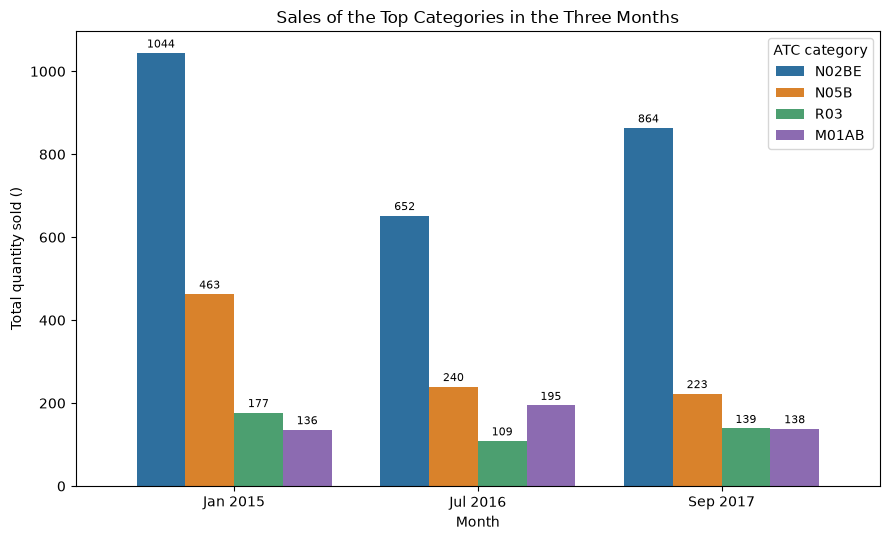

In [70]:
fig, ax = plt.subplots(figsize=(9, 5.5))

q3_table.T.plot(kind="bar", ax=ax, width=0.8, rot=0,
                color=["#2E6F9E", "#D9822B", "#4C9F70", "#8C6BB1"])

for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8, padding=2)

ax.set_title("Sales of the Top Categories in the Three Months")
ax.set_xlabel("Month")
ax.set_ylabel("Total quantity sold ()")
ax.legend(title="ATC category")

plt.tight_layout()
plt.savefig("../visualisations/q3_top_categories_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart 4:** N02BE and N05B are first and second in all three months. Third place changes: R03 in Jan 2015 and Sep 2017, M01AB in Jul 2016.

**Finding:**

| Rank | January 2015 | July 2016 | September 2017 |
|---|---|---|---|
| 1 | N02BE (1,044) | N02BE (652) | N02BE (864) |
| 2 | N05B (463) | N05B (240) | N05B (223) |
| 3 | R03 (177) | M01AB (195) | R03 (139) |

N02BE was first and N05B was second in all three months. Only third place changed: R03 in January 2015 and September 2017, and M01AB in July 2016. In July 2016, R03 dropped to 7th place with 109 units.

**Limitations:**
- These are categories, not individual drugs, so this doesn't tell me which brand sold the most.
- Third place in September 2017 is very close (R03 139.0 vs M01AB 138.3), so it could easily change with slightly different sales.
- Each result comes from only one month, so I can't say these months are typical. The R03 drop in July 2016 is just one observation, and I test the seasonal pattern properly in Question 6.
- The unit of the sales numbers isn't documented.

## 7. Question 4: Which drug was sold most often in 2017? (answered at category level)

**Note:** As before, the dataset has drug **categories**, not individual drugs. Also, "sold most often" can mean two things, so I calculated both:
1. **Highest total quantity** sold in 2017.
2. **Most days with recorded sales above zero** in 2017.

**Approach:** I filtered the data to 2017 (365 days, a full year), added up each category's sales for the total, and counted the days where sales were above zero for each category.

In [52]:
sales_2017 = df[df["Year"] == 2017]
len(sales_2017)

365

In [53]:
# Interpretation 1: highest total quantity
total_2017 = sales_2017[drug_cols].sum().sort_values(ascending=False)
total_2017.round(2)

N02BE    9258.80
N05B     2555.54
R03      1893.61
M01AB    1846.62
M01AE    1387.30
N02BA    1288.30
R06       988.86
N05C      180.33
dtype: float64

In [54]:
# Interpretation 2: number of days with sales above zero
days_2017 = (sales_2017[drug_cols] > 0).sum().sort_values(ascending=False)
days_2017

N02BE    361
M01AB    360
M01AE    360
N05B     356
N02BA    350
R06      329
R03      286
N05C      99
dtype: int64

In [55]:
# Both side by side
summary_2017 = pd.DataFrame({
    "total": total_2017.round(2),
    "days_with_sales": days_2017,
    "pct_of_days": (days_2017 / len(sales_2017) * 100).round(1)
}).sort_values("total", ascending=False)
summary_2017

,total,days_with_sales,pct_of_days
N02BE,9258.80,361,98.9
N05B,2555.54,356,97.5
R03,1893.61,286,78.4
M01AB,1846.62,360,98.6
M01AE,1387.30,360,98.6
N02BA,1288.30,350,95.9
R06,988.86,329,90.1
N05C,180.33,99,27.1


**Finding:** N02BE is the answer under both meanings. It had the highest total (9,259 units, 47.7% of all 2017 sales) and the most days with sales (361 out of 365 days). On the days measure the top is very close: M01AB and M01AE had 360 days each, only one day less. R03 is third by total (1,894) but only seventh by days with sales (286), which means it sells in larger amounts on the days it does sell.

**Limitations:**
- These are categories, not individual drugs.
- Counting days with sales above zero only tells me how often a category sold, not how much. Almost every category sells on most days, so this measure doesn't separate the top categories well (the top three are within one day of each other).
- A zero could mean no demand, no stock or a closed pharmacy, and the data can't tell me which.
- The unit of the sales numbers isn't documented.

## 8. Question 5: Which drug category has the highest average daily sales?

**Approach:** I took the mean of each category over all 2,106 days. I kept the zero-sales days in, because a zero means nothing was sold that day, and removing them would make rarely sold categories look busier than they are. To check this, I also calculated the average using only the days with sales, and compared the mean with the median and standard deviation to see how well the average describes a typical day.

In [56]:
avg_daily = df[drug_cols].mean().sort_values(ascending=False).round(2)
avg_daily

N02BE    29.92
N05B      8.85
R03       5.51
M01AB     5.03
M01AE     3.90
N02BA     3.88
R06       2.90
N05C      0.59
dtype: float64

In [57]:
# Is the average a fair summary? Compare mean, median and spread
summary_avg = pd.DataFrame({
    "mean": df[drug_cols].mean().round(2),
    "median": df[drug_cols].median().round(2),
    "std": df[drug_cols].std().round(2),
    "mean_days_with_sales": df[drug_cols].where(df[drug_cols] > 0).mean().round(2)
}).sort_values("mean", ascending=False)
summary_avg

,mean,median,std,mean_days_with_sales
N02BE,29.92,26.90,15.59,30.29
N05B,8.85,8.00,5.61,9.04
R03,5.51,4.00,6.43,7.16
M01AB,5.03,4.99,2.74,5.13
M01AE,3.90,3.67,2.13,3.96
N02BA,3.88,3.50,2.38,4.03
R06,2.90,2.00,2.42,3.30
N05C,0.59,0.00,1.09,1.85


In [58]:
# How many times bigger is the top category than the second?
(avg_daily.iloc[0] / avg_daily.iloc[1]).round(2)

np.float64(3.38)

### Extra: average daily sales by year

In [59]:
trend = df.groupby("Year")[["N02BE", "N05B", "R03"]].mean().round(2)
trend

,N02BE,N05B,R03
Year,,,
2014,25.48,11.85,3.45
2015,32.67,8.12,4.72
2016,36.44,8.57,5.84
2017,25.37,7.00,5.19
2018,30.77,8.95,7.27
2019,28.41,8.56,6.93


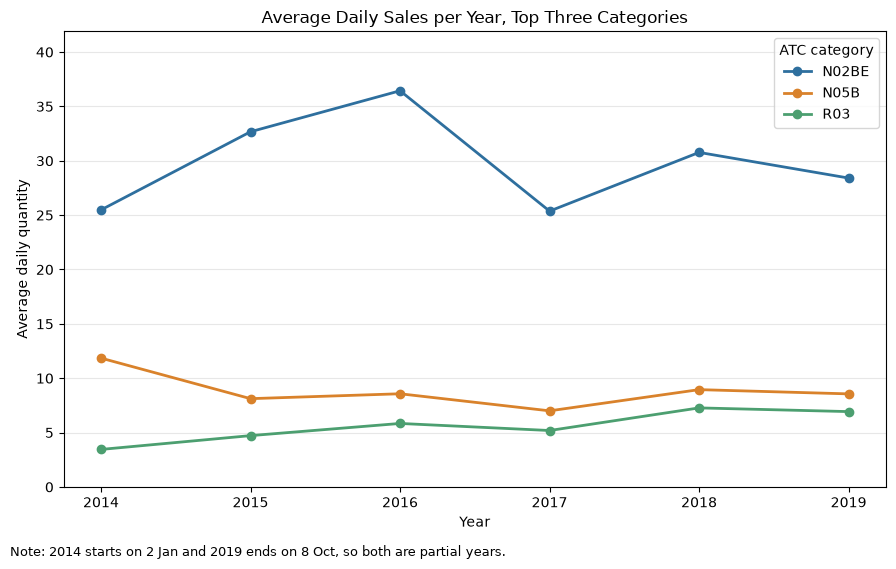

In [69]:
fig, ax = plt.subplots(figsize=(9, 5.5))

trend.plot(ax=ax, marker="o", linewidth=2,
           color=["#2E6F9E", "#D9822B", "#4C9F70"])

ax.set_title("Average Daily Sales per Year, Top Three Categories")
ax.set_xlabel("Year")
ax.set_ylabel("Average daily quantity")
ax.set_xticks(trend.index)
ax.set_ylim(0, trend.max().max() * 1.15)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="ATC category")

fig.text(0.01, -0.02,
         "Note: 2014 starts on 2 Jan and 2019 ends on 8 Oct, so both are partial years.",
         fontsize=9)

plt.tight_layout()
plt.savefig("../visualisations/trend_top3_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart 5:** R03's daily average rose from 3.45 in 2014 to 7.27 in 2018. N02BE and N05B show no steady direction. 2014 and 2019 are partial years.

**Finding:** N02BE has the highest average daily sales at 29.92 per day, about 3.4 times more than the second category, N05B (8.85). R03 is third with 5.51 per day, and N05C is the lowest at 0.59. N02BE is first whether or not I include zero days. For N02BE the mean (29.92) is close to the median (26.90), so the average is a fair picture of a typical day.

**Limitations:**
- Averages hide day-to-day differences. R03 has a mean of 5.51 but a median of 4.00 and a standard deviation of 6.43, so a few very large days pull its average up, and a typical R03 day is lower than its average.
- N05C is zero on 67.9% of days, so its mean of 0.59 is very small. On days when it does sell, it averages 1.85.
- These are categories, not individual drugs, and the unit of the numbers isn't documented, so the categories may not be directly comparable.
- The average covers 2,106 days from 2 Jan 2014 to 8 Oct 2019, so it doesn't reflect changes over time (for example, R03's yearly average rose from 3.45 in 2014 to 7.27 in 2018).

## 9. Question 6: Are respiratory drugs (R03) sold more during specific months?

**Approach:** Comparing monthly totals directly is unfair here, because months have different numbers of days and the data stops on 8 Oct 2019 (so Nov and Dec 2019 are missing). A simple total per month over all the data actually shows January as the highest (1,265), but that is only because January has more days and more years of data than December. To compare months fairly, I used only the four complete years (2015 to 2018) and looked at the average monthly total and the daily average for each month. I also made a seasonal index (each month's daily average divided by the overall daily average of 5.75), and I checked each year separately to see whether the pattern repeats.

In [61]:
# The naive version: total per month over all the data (unfair, see the approach above)
r03_naive = pd.DataFrame({
    "total": df.groupby("Month")["R03"].sum().round(1),
    "days": df.groupby("Month")["R03"].count()
})
r03_naive

,total,days
Month,,
1,1264.7,185
2,1165.6,169
3,1170.0,186
4,1038.9,180
5,931.3,186
6,783.0,180
7,550.0,186
8,577.0,186
9,792.4,180


In [62]:
full_years = df[df["Year"].between(2015, 2018)]
monthly_totals = full_years.groupby(["Year", "Month"])["R03"].sum().unstack()
monthly_totals.mean().round(1)

Month
1     191.7
2     204.4
3     200.2
4     180.7
5     131.5
6     146.0
7      93.5
8      98.8
9     139.0
10    244.5
11    205.5
12    266.0
dtype: float64

In [63]:
summary_r03 = pd.DataFrame({
    "avg_monthly_total": monthly_totals.mean().round(1),
    "daily_mean": full_years.groupby("Month")["R03"].mean().round(2),
    "median": full_years.groupby("Month")["R03"].median(),
    "pct_zero_days": ((full_years["R03"] == 0).groupby(full_years["Month"]).mean() * 100).round(1)
})
summary_r03["seasonal_index"] = (summary_r03["daily_mean"] / full_years["R03"].mean()).round(2)
summary_r03.sort_values("daily_mean", ascending=False)

,avg_monthly_total,daily_mean,median,pct_zero_days,seasonal_index
Month,,,,,
12,266.0,8.58,7.0,15.3,1.49
10,244.5,7.89,6.0,9.7,1.37
2,204.4,7.24,6.0,14.2,1.26
11,205.5,6.85,5.0,15.8,1.19
3,200.2,6.46,5.0,17.7,1.12
1,191.7,6.18,5.0,14.5,1.07
4,180.7,6.02,5.0,14.2,1.05
6,146.0,4.87,3.5,20.8,0.85
9,139.0,4.63,3.0,23.3,0.80


In [64]:
within_year = (
    full_years.groupby(["Year", "Month"])["R03"].mean().unstack()
    .div(full_years.groupby("Year")["R03"].mean(), axis=0)
    .round(2)
)
within_year

Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2015,1.21,1.58,1.16,0.69,0.68,1.36,0.41,0.31,0.64,1.26,1.17,1.58
2016,0.96,1.45,1.40,1.23,0.72,0.73,0.60,0.64,0.69,1.22,0.86,1.52
2017,1.22,0.97,0.68,1.16,0.80,1.05,0.72,0.47,0.89,1.54,1.26,1.27
2018,0.97,1.10,1.19,1.05,0.74,0.46,0.40,0.71,0.94,1.45,1.43,1.57


In [65]:
within_year.idxmin(axis=1), within_year.idxmax(axis=1)

(Year
 2015    8
 2016    7
 2017    8
 2018    7
 dtype: int64,
 Year
 2015     2
 2016    12
 2017    10
 2018    12
 dtype: int64)

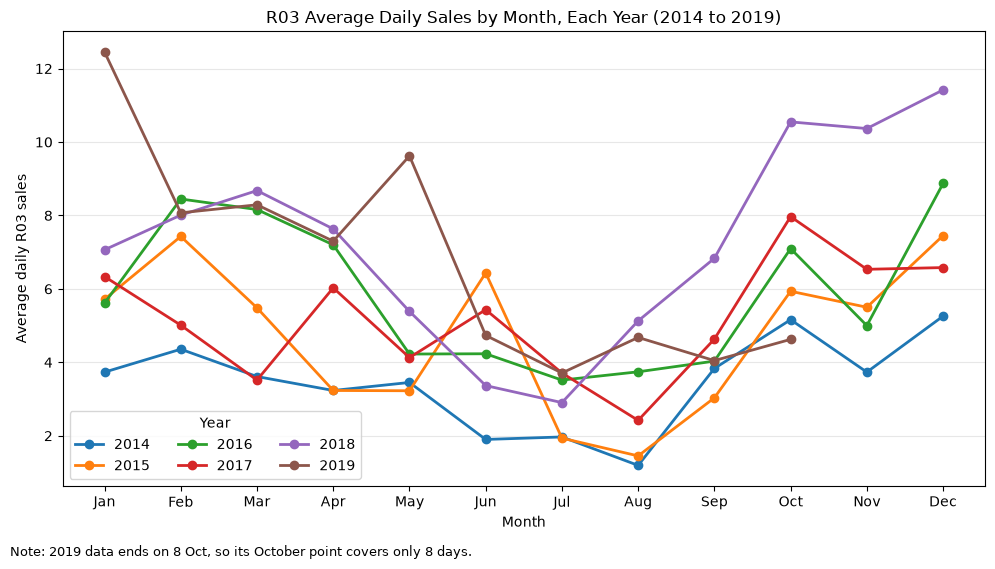

In [68]:
monthly = df.groupby(["Year", "Month"])["R03"].mean().unstack()
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(10, 5.5))

for year in monthly.index:
    ax.plot(monthly.columns, monthly.loc[year], marker="o", linewidth=2, label=year)

ax.set_title("R03 Average Daily Sales by Month, Each Year (2014 to 2019)")
ax.set_xlabel("Month")
ax.set_ylabel("Average daily R03 sales")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Year", ncol=3)

fig.text(0.01, -0.02,
         "Note: 2019 data ends on 8 Oct, so its October point covers only 8 days.",
         fontsize=9)

plt.tight_layout()
plt.savefig("../visualisations/q6_r03_monthly_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart 2:** Each line is one year of R03 sales. In every year the line dips around July and August and rises from October. The 2019 line stops in October because the data ends on 8 Oct 2019.

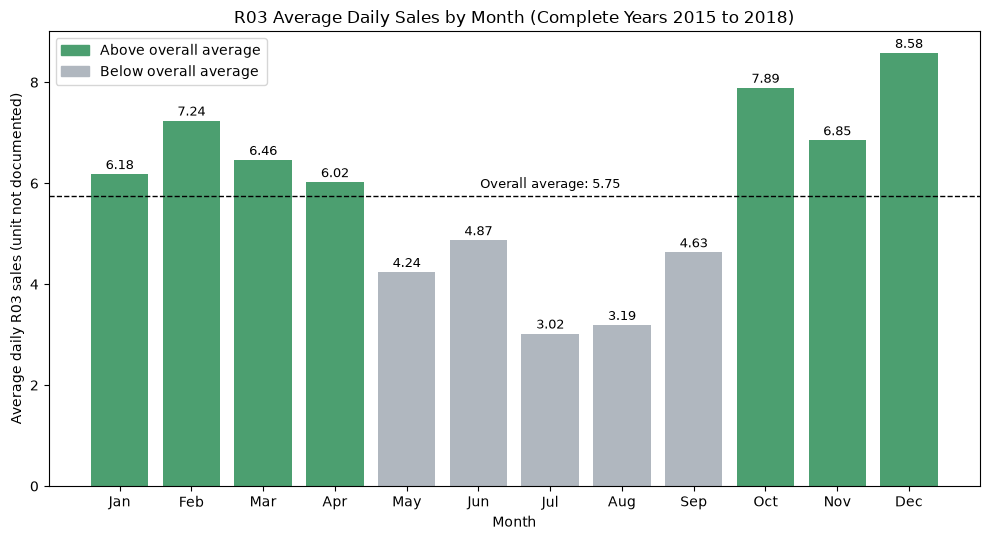

In [67]:
season = full_years.groupby("Month")["R03"].mean().round(2).sort_index()
overall = full_years["R03"].mean()
colors = ["#4C9F70" if v > overall else "#B0B7BF" for v in season.values]

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.bar(month_names, season.values, color=colors)
ax.axhline(overall, color="black", linestyle="--", linewidth=1)
ax.text(6, overall + 0.15, f"Overall average: {overall:.2f}", ha="center", fontsize=9)

for i, v in enumerate(season.values):
    ax.text(i, v + 0.1, f"{v:.2f}", ha="center", fontsize=9)

ax.set_title("R03 Average Daily Sales by Month (Complete Years 2015 to 2018)")
ax.set_xlabel("Month")
ax.set_ylabel("Average daily R03 sales (unit not documented)")
ax.legend(handles=[Patch(color="#4C9F70", label="Above overall average"),
                   Patch(color="#B0B7BF", label="Below overall average")])

plt.tight_layout()
plt.savefig("../visualisations/q6_r03_seasonal_bars.png", dpi=150, bbox_inches="tight")
plt.show()

**Chart 3:** Using only complete years (2015 to 2018), R03 is above its overall average from October to April and below it from May to September. December is highest (8.58) and July is lowest (3.02).

**Finding:** Yes, R03 sales show a clear seasonal pattern. December has the highest daily average (8.58 per day), followed by October (7.89) and February (7.24). July has the lowest (3.02), followed by August (3.19) and May (4.24). The seven months from October to April are all above the overall average, and the five months from May to September are all below it. December's daily average is about 2.8 times July's. Zero-sales days follow the same pattern: 38.7% of July days had no R03 sales compared with 9.7% in October. The pattern also shows up in each year separately: July or August was the lowest month in all four complete years, and the highest month was always December, October or February.

**Possible explanation (not proven by this data):** R03 treats breathing problems, so higher sales in the colder months could be linked to colds and other respiratory illness, but the dataset has no weather or illness data, so I can't confirm this.

**Limitations:**
- The pattern is based on only four complete years (2015 to 2018), so it may not hold in other years. The pattern is not identical every year: for example, in 2017 March was low, and in 2015 December and February were tied for the top.
- R03's overall level rose between 2014 and 2018, so I compared months within each year to make sure the pattern isn't just growth over time.
- The dataset doesn't say where the sales come from, so I can't say which season the months match, and I can't link the pattern to weather.
- The data shows when R03 sold more, not why.
- These are categories (ATC codes) and the unit of the numbers isn't documented.

## 10. Business Insights and Conclusions

### What the data shows
- **One category dominates.** N02BE sold 63,005 units, which is 49.4% of all sales. It averaged 29.92 per day, about 3.4 times more than the second category, N05B (8.85). N02BE was first and N05B was second in every year from 2014 to 2019.
- **R03 sales are seasonal.** Using the complete years 2015 to 2018, R03 averaged 7.03 per day from October to April and 3.98 per day from May to September. December was the highest month (8.58 per day) and July was the lowest (3.02). This pattern appeared in every complete year, though not identically each time.
- **R03 rose over the years.** Its daily average went from 3.45 in 2014 to 7.27 in 2018 (6.93 in 2019, which is a partial year). N02BE and N05B did not show a steady direction.
- **Some days are unusual.** The five highest N02BE days fall into two short periods around the end of the year (30 to 31 Dec 2016 and 20 to 27 Jan 2019), with a peak of 161 on 30 Dec 2016.
- **N05C rarely sells.** It had no sales on 67.9% of days.

### Possible explanations
- R03's seasonal pattern could be linked to colds and other respiratory illness in the colder months, but the dataset has no illness or weather data.
- The N02BE peaks around the new year could be a holiday rush, a bulk order, or a shortage elsewhere. The data can't tell these apart.
- N05C's many zero days could mean low demand, low stock, or something else.

### What this could mean for a pharmacy
- If the R03 pattern continues, it might be worth checking that R03 stock is high going into October.
- N02BE is the biggest category by far, so it is likely the most important to keep in stock.
- Before deciding anything about N05C, I would need price, profit and stock data, because sales quantity alone doesn't show whether a product is worth stocking.

### What I can't say
- I can't say which individual drug or brand sold the most, because the data only has categories.
- I can't say why any pattern happens, only that it appears in the data.
- I can't say anything about R06, N02BA and the other categories by month, because I didn't analyse them that way.

## 11. Limitations

### Limitations
- **Categories, not brands.** The data has ATC codes only, so brand-level questions can't be answered.
- **Unknown units.** The unit of the sales numbers isn't documented, and many values are decimals, so I don't know what is being counted or whether categories are directly comparable.
- **Unknown source.** The dataset doesn't say which pharmacy or place the sales come from, so the results may not apply elsewhere.
- **Partial years.** The data runs from 2 Jan 2014 to 8 Oct 2019, so 2014 and 2019 are incomplete. I used daily averages and complete years where it mattered.
- **Only four complete years.** The seasonal pattern for R03 is based on 2015 to 2018, which isn't a long history.
- **Zeros are unclear.** A zero could mean no demand, no stock or a closed day, and the data can't tell me which.
- **Unexplained column.** The `Hour` column has no description, so I didn't use it.
- **Descriptive only.** This project describes what happened. It doesn't test why, and it doesn't predict the future.